# 05 — Model stability, feature ablation and tuning

**Hypotheses:** (H1) X-learner có lợi khi treatment/control lệch 75/25; (H2) causal candidate chỉ đáng
giữ nếu thắng risk baseline qua nhiều seeds; (H3) feature compression/regularization phải tăng stability,
không chỉ một lucky Qini.

Tất cả thí nghiệm dùng 9.516 development rows. Holdout đã mở ở notebook 03 không được dùng để chọn lại
model; mọi winner mới chỉ là future challenger.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
STABILITY = ROOT / "reports/uplift/stability"
TUNING = ROOT / "reports/uplift/tuning"
TOURNAMENT = ROOT / "reports/uplift/tournament"
ABLATION = ROOT / 'reports/uplift/component_ablation'

## 1. Repeated OOF protocol

5 repeats × 3 stratified folds. Mỗi repeat refit cross-fitted nuisance outcomes và toàn bộ risk/T/S/DR/X
scores. Primary là Qini-DR; IPW là sensitivity; supporting gồm positive-rate, mean rank, uplift@20 và
paired win-rate so với risk-logistic.

In [2]:
stability_meta = json.loads((STABILITY / "stability_summary.json").read_text(encoding="utf-8"))
stability = pd.read_csv(STABILITY / "repeated_oof_summary.csv")
display(pd.Series(stability_meta).to_frame("value"))
display(stability)

,value
repeats,5
folds,3
test_rows_touched,0
best_mean_qini_model,risk_logistic
best_mean_qini,0.002668
risk_logistic_mean_qini,0.002668


,model,qini_dr_mean,qini_dr_std,qini_ipw_mean,qini_ipw_std,qini_dr_positive_rate,mean_rank,uplift_at_20_mean,uplift_at_20_std,delta_vs_risk_mean,beats_risk_rate
0,risk_logistic,0.002668,0.000938,0.003071,0.000545,1.0,1.0,0.010745,0.009498,0.000000,0.0
1,x_hgb,0.000008,0.000754,-0.001125,0.001220,0.4,3.4,0.009572,0.008839,-0.002660,0.0
2,dr_hgb,-0.000398,0.001059,-0.001096,0.001542,0.4,4.0,0.004742,0.004806,-0.003065,0.0
3,s_hgb,-0.000421,0.000538,0.003919,0.000169,0.2,3.8,-0.001864,0.005427,-0.003088,0.0
4,random,-0.000596,0.002797,-0.001382,0.002375,0.4,3.4,0.003133,0.011517,-0.003263,0.0
5,t_logistic,-0.001624,0.000803,-0.002341,0.000929,0.0,5.4,0.001756,0.008107,-0.004292,0.0


## 2. Seed distribution, không chỉ mean

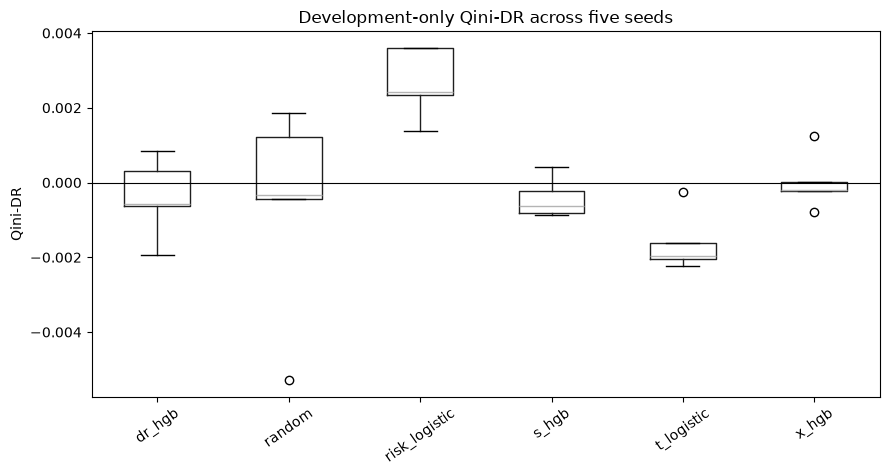

In [3]:
raw = pd.read_csv(STABILITY / "repeated_oof_raw.csv")
order = stability.sort_values("qini_dr_mean", ascending=False)["model"].tolist()
fig, ax = plt.subplots(figsize=(9, 5))
raw.boxplot(column="qini_dr", by="model", ax=ax, grid=False, rot=35)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Development-only Qini-DR across five seeds")
ax.set_xlabel("")
ax.set_ylabel("Qini-DR")
fig.suptitle("")
plt.tight_layout()
plt.show()

In [4]:
paired = raw.pivot(index="repeat", columns="model", values="qini_dr")
for model in [c for c in paired if c != "risk_logistic"]:
    paired[f"delta_{model}_vs_risk"] = paired[model] - paired["risk_logistic"]
display(paired[[c for c in paired if c.startswith("delta_")]])

model,delta_dr_hgb_vs_risk,delta_random_vs_risk,delta_s_hgb_vs_risk,delta_t_logistic_vs_risk,delta_x_hgb_vs_risk
repeat,,,,,
0,-0.002030,-0.007620,-0.003209,-0.002589,-0.002538
1,-0.001967,-0.001722,-0.001611,-0.003443,-0.000143
2,-0.001578,-0.000566,-0.003230,-0.004385,-0.002633
3,-0.004214,-0.004019,-0.003159,-0.005832,-0.004385
4,-0.005537,-0.002388,-0.004234,-0.005209,-0.003599


## 3. Estimator agreement gate

Qini-IPW dương nhưng Qini-DR âm là instability signal, không phải cơ hội chọn estimator có kết quả đẹp.
S-HGB rơi đúng trường hợp này; X-HGB gần zero và không thắng risk ở seed nào.

In [5]:
display(stability[["model", "qini_dr_mean", "qini_dr_std", "qini_ipw_mean",
                   "qini_ipw_std", "qini_dr_positive_rate", "mean_rank", "beats_risk_rate"]])

,model,qini_dr_mean,qini_dr_std,qini_ipw_mean,qini_ipw_std,qini_dr_positive_rate,mean_rank,beats_risk_rate
0,risk_logistic,0.002668,0.000938,0.003071,0.000545,1.0,1.0,0.0
1,x_hgb,0.000008,0.000754,-0.001125,0.001220,0.4,3.4,0.0
2,dr_hgb,-0.000398,0.001059,-0.001096,0.001542,0.4,4.0,0.0
3,s_hgb,-0.000421,0.000538,0.003919,0.000169,0.2,3.8,0.0
4,random,-0.000596,0.002797,-0.001382,0.002375,0.4,3.4,0.0
5,t_logistic,-0.001624,0.000803,-0.002341,0.000929,0.0,5.4,0.0


## 4. Risk-logistic tuning matrix

24 configs = 4 feature sets × 6 values of C; mỗi config chạy 3 seeds × 3 folds. Tuning objective vẫn là
policy Qini-DR, không phải AUC. `PC1..PCk` chỉ là variance-order ablation, không business feature
selection.

In [6]:
tuning = pd.read_csv(TUNING / "risk_logistic_tuning_summary.csv")
decision = json.loads((TUNING / "tuning_decision.json").read_text(encoding="utf-8"))
display(tuning.head(15))
display(pd.Series(decision["recommended_future_challenger"]).to_frame("value"))

,feature_set,feature_count,C,qini_dr_mean,qini_dr_std,qini_ipw_mean,qini_ipw_std,uplift_at_20_mean,uplift_at_20_std
0,all_178,178,3.00,0.003007,0.000917,0.003366,0.000777,0.024760,0.002202
1,all_178,178,1.00,0.002965,0.000971,0.003338,0.000812,0.024840,0.005258
2,all_178,178,0.30,0.002766,0.000959,0.003222,0.000814,0.022813,0.008306
3,all_178,178,0.10,0.002271,0.000920,0.002844,0.000762,0.014348,0.002498
4,all_178,178,0.03,0.001392,0.000895,0.002006,0.000812,0.010443,0.006327
5,pc40_plus_factors,58,1.00,0.001185,0.001078,0.002192,0.001239,0.010892,0.011705
6,pc40_plus_factors,58,0.30,0.001108,0.000953,0.002130,0.000917,0.009298,0.008307
7,pc40_plus_factors,58,3.00,0.001086,0.001154,0.002084,0.001427,0.007182,0.013090
8,pc20_plus_factors,38,0.30,0.001044,0.000589,0.002160,0.000653,0.009383,0.010351
9,pc20_plus_factors,38,1.00,0.000964,0.000907,0.002186,0.000964,0.004735,0.014742


,value
feature_set,all_178
feature_count,178
C,0.3
qini_dr_mean,0.002766
qini_dr_std,0.000959


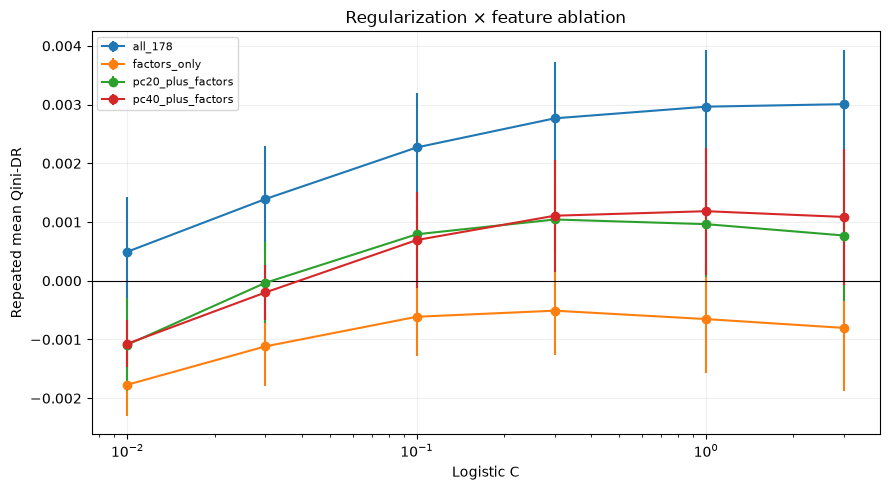

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for feature_set, part in tuning.groupby("feature_set"):
    part = part.sort_values("C")
    ax.errorbar(part["C"], part["qini_dr_mean"], yerr=part["qini_dr_std"], marker="o", label=feature_set)
ax.set_xscale("log")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="Logistic C", ylabel="Repeated mean Qini-DR", title="Regularization × feature ablation")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Full model-family tournament

14 cấu hình phủ risk/S/T/transformed-outcome/DR/R/X và Logistic/RF/HGB/CatBoost/ExtraTrees. Đây là
development-only screen; Qini-DR là primary, IPW là sensitivity, 20% là reference capacity. `basic_gate`
không đồng nghĩa đủ launch.

In [8]:
tournament = pd.read_csv(TOURNAMENT / "tournament_summary.csv")
tournament_decision = json.loads(
    (TOURNAMENT / "tournament_decision.json").read_text(encoding="utf-8")
)
display(tournament[["model", "family", "qini_dr_mean", "qini_dr_std", "qini_ipw_mean",
                    "delta_vs_risk_mean", "delta_vs_risk_ci95_low", "beats_risk_rate",
                    "dr_uplift_20_mean", "runtime_seconds_mean", "basic_gate"]])
display(pd.Series(tournament_decision).to_frame("value"))

,model,family,qini_dr_mean,qini_dr_std,qini_ipw_mean,delta_vs_risk_mean,delta_vs_risk_ci95_low,beats_risk_rate,dr_uplift_20_mean,runtime_seconds_mean,basic_gate
0,risk_logistic,risk,0.002707,0.001025,0.003291,0.000000,0.000000,0.0,0.016328,0.448823,True
1,risk_catboost,risk,0.001427,0.000455,0.001873,-0.001280,-0.002832,0.0,0.016408,31.936002,True
2,risk_hgb,risk,0.001379,0.000266,0.001815,-0.001328,-0.003213,0.0,0.008425,1.443650,True
3,risk_rf,risk,0.001175,0.000569,0.001658,-0.001532,-0.004472,0.0,0.006041,3.123339,True
4,dr_hgb,dr_learner,0.001122,0.000797,0.000560,-0.001585,-0.003355,0.0,0.014782,4.794576,True
5,dr_extratrees,dr_learner,0.000991,0.000176,0.000963,-0.001716,-0.004623,0.0,0.013710,7.195656,True
6,to_hgb,transformed_outcome,0.000639,0.001000,0.001351,-0.002068,-0.006875,0.0,0.010270,2.286639,False
7,s_logistic,s_learner,0.000427,0.000403,-0.000505,-0.002280,-0.003841,0.0,0.007412,3.528839,False
8,r_hgb,r_learner,0.000021,0.001665,-0.000440,-0.002686,-0.004382,0.0,-0.000792,4.965570,False
9,t_logistic,t_learner,-0.000029,0.000191,-0.000998,-0.002736,-0.005148,0.0,0.007816,1.333996,False


,value
development_champion,risk_logistic
mean_best_model,risk_logistic
one_standard_error_floor,0.002115
selection_reason,simplest model within one SE of best eligible ...
causal_replacement,none
causal_replacement_gate,paired Qini-DR delta lower 95% CI > 0 and wins...
profile,full
candidate_count,14
repeats,3
folds,3


## 6. Thuật toán con và evaluator sensitivity

Giữ nguyên policy OOF scores, thay common nuisance evaluator giữa Logistic, HGB và CatBoost. Brier/log-loss
chọn nuisance; minimum Qini qua evaluator chọn robust component. Không được lấy evaluator làm model ưa thích
đẹp hơn.

In [9]:
nuisance = pd.read_csv(ABLATION / "nuisance_diagnostics_summary.csv")
robustness = pd.read_csv(ABLATION / "model_evaluator_robustness.csv")
components = pd.read_csv(ABLATION / "component_winners.csv")
display(nuisance)
display(robustness)
display(components)

,nuisance_model,factual_ap_mean,factual_ap_std,factual_brier_mean,factual_brier_std,factual_log_loss_mean,dr_score_std_mean
0,catboost,0.149259,0.008896,0.031173,0.000124,0.126412,0.421594
1,hgb,0.148662,0.016025,0.031333,0.000208,0.129073,0.422475
2,logistic,0.126322,0.005465,0.034984,0.000733,0.155539,0.444181


,model,qini_all_mean,qini_between_evaluator_std,minimum_evaluator_qini,maximum_evaluator_qini,positive_evaluator_count,positive_across_all_evaluators
0,risk_logistic,0.002679,0.000118,0.002550,0.002781,3,True
1,risk_catboost,0.001635,0.000184,0.001427,0.001777,3,True
2,risk_hgb,0.001634,0.000224,0.001379,0.001800,3,True
3,risk_rf,0.001345,0.000164,0.001175,0.001503,3,True
4,dr_extratrees,0.000826,0.000145,0.000720,0.000991,3,True
5,to_hgb,0.000695,0.000086,0.000639,0.000794,3,True
6,dr_hgb,0.000562,0.000485,0.000264,0.001122,3,True
7,r_hgb,-0.000316,0.000300,-0.000552,0.000021,1,False
8,s_logistic,-0.000279,0.000614,-0.000686,0.000427,1,False
9,t_hgb,-0.000647,0.000109,-0.000743,-0.000528,0,False


,component,winner,selection_metric,minimum_evaluator_qini,qini_all_mean,positive_across_all_evaluators,decision
0,risk base learner,risk_logistic,maximum worst-evaluator mean Qini-DR,0.002550,0.002679,True,retain for confirmation
1,S-learner base learner,s_logistic,maximum worst-evaluator mean Qini-DR,-0.000686,-0.000279,False,no robust winner
2,T-learner base learner,t_hgb,maximum worst-evaluator mean Qini-DR,-0.000743,-0.000647,False,no robust winner
3,DR second-stage learner,dr_extratrees,maximum worst-evaluator mean Qini-DR,0.000720,0.000826,True,retain for confirmation
4,causal meta-learner,dr_extratrees,maximum worst-evaluator mean Qini-DR,0.000720,0.000826,True,retain for confirmation


## 7. Decision

- Risk-logistic mean Qini-DR 0,002668, dương 5/5, mean rank 1,0.
- X-HGB mean 0,000008, dương 2/5, thắng risk 0/5: H1 bị bác bỏ trên dataset này.
- S-HGB IPW/DR khác dấu: reject vì estimator sensitivity.
- Best tuning mean là all-178/C=3; one-standard-error rule giữ all-178/C=0,3 — đúng current baseline,
  tránh đổi model vì improvement nhỏ/variance lớn.
- Tournament/ablation winner là **future challenger**, không sửa champion cũ sau khi holdout đã mở. Một causal
  replacement còn phải có paired delta lower CI > 0, thắng ≥80% repeats và giữ dấu qua mọi evaluator.
- Không retest holdout. Challenger tiếp theo cần campaign/time split mới; nếu không có, dừng tuning.